In [1]:
# environment

import copy
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import resnet18

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

torch.manual_seed(42)

print("Device:", device)
print("PyTorch:", torch.__version__)


Device: mps
PyTorch: 2.11.0



### ResNet-18 Backbone 与 Projection Head

由于 CIFAR-10 数据集中的图像分辨率仅为 **32 × 32**，原始 ResNet-18 的输入层使用 $7 \times 7$ 卷积（stride = 2）和 MaxPooling，会过早降低特征图的空间分辨率，造成部分细节信息丢失。

因此，我们对 ResNet-18 的输入结构进行以下调整：

1. **卷积层（Conv1）**：将原始的 $7 \times 7$ 卷积替换为 $3 \times 3$ 卷积，并设置 stride = 1、padding = 1。
2. **最大池化层（MaxPool）**：移除初始 MaxPooling，避免过早下采样。
3. **分类层（FC）**：移除原始分类层，保留 Backbone 输出的 512 维特征。
4. **投影头（Projection Head）**：使用两层 MLP，将 512 维特征映射到 128 维对比学习空间。
5. **L2 Normalization**：对最终特征进行归一化，使其位于单位超球面上，便于计算余弦相似度。

#### 网络数据流

**输入图像：**

$$
x \in \mathbb{R}^{B \times 3 \times 32 \times 32}
$$

其中，$B$ 表示 Batch Size，3 表示 RGB 通道数。

**ResNet-18 Backbone 特征提取：**

$$
h = f_{\theta}(x), \qquad
h \in \mathbb{R}^{B \times 512}
$$

**Projection Head 特征映射：**

$$
z' = g_{\theta}(h), \qquad
z' \in \mathbb{R}^{B \times 128}
$$

**L2 归一化：**

$$
z = \frac{z'}{\|z'\|_2}
$$

归一化后：

$$
\|z_i\|_2 = 1
$$

因此，两个特征向量之间的余弦相似度可以直接通过点积计算：

$$
\operatorname{sim}(z_i,z_j) = z_i^\top z_j
$$

#### 设计目的

该结构将 **特征提取（Backbone）** 与 **对比学习特征映射（Projection Head）** 分离：

- Backbone 学习图像的视觉表征。
- Projection Head 将视觉特征映射到对比学习空间，用于计算 InfoNCE Loss。
- L2 Normalization 保证特征向量具有单位长度，使相似度计算更加直接。

在后续的 Linear Probing 实验中，我们将主要使用 Backbone 输出的 512 维特征 $h$，而不是 Projection Head 输出的 128 维向量 $z$，以评估自监督预训练所学习的视觉表征质量。


In [2]:
# ResNet-18 Encoder

class ContrastiveEncoder(nn.Module):
    def __init__(self, feature_dim=128):
        super().__init__()

        self.backbone = resnet18(weights=None)

        # Adapt ResNet-18 for CIFAR-10 (32x32)
        self.backbone.conv1 = nn.Conv2d(
            3, 64, kernel_size=3,
            stride=1, padding=1, bias=False
        )
        self.backbone.maxpool = nn.Identity()

        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        # Two-layer projection head
        self.projector = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, feature_dim)
        )

    def forward(self, x):
        h = self.backbone(x)
        z = self.projector(h)

        # Unit-length embeddings for cosine similarity
        return F.normalize(z, dim=1)


In [4]:
# 验证encoder

encoder = ContrastiveEncoder(feature_dim=128).to(device)

# Simulate a batch of 4 CIFAR-10 images
sample_images = torch.randn(
    4, 3, 32, 32,
    device=device
)

encoder.eval()

with torch.no_grad():
    embeddings = encoder(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", embeddings.shape)
print("Feature norms:", embeddings.norm(dim=1).cpu())

# Verify output dimensions
assert embeddings.shape == (4, 128)

# Verify L2 normalization
assert torch.allclose(
    embeddings.norm(dim=1),
    torch.ones(4, device=device),
    atol=1e-5
)

print("Encoder validation passed!")



Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 128])
Feature norms: tensor([1.0000, 1.0000, 1.0000, 1.0000])
Encoder validation passed!


In [5]:
# 实现完整MOCO

class MoCo(nn.Module):
    def __init__(
        self,
        feature_dim=128,
        queue_size=1024,
        momentum=0.999,
        temperature=0.2
    ):
        super().__init__()

        assert queue_size > 0
        assert 0 < momentum < 1
        assert temperature > 0

        self.momentum = momentum
        self.temperature = temperature
        self.queue_size = queue_size

        # 1. Two encoders
        self.encoder_q = ContrastiveEncoder(feature_dim)
        self.encoder_k = copy.deepcopy(self.encoder_q)

        # Key encoder is not updated by gradients
        for param in self.encoder_k.parameters():
            param.requires_grad = False

        # 2. Initialize normalized negative queue
        queue = torch.randn(feature_dim, queue_size)
        queue = F.normalize(queue, dim=0)

        self.register_buffer("queue", queue)
        self.register_buffer(
            "queue_ptr", torch.zeros(1, dtype=torch.long)
        )

    @torch.no_grad()
    def momentum_update(self):
        # EMA parameter update
        for p_q, p_k in zip(
            self.encoder_q.parameters(),
            self.encoder_k.parameters()
        ):
            p_k.data.mul_(self.momentum).add_(
                p_q.data, alpha=1 - self.momentum
            )

    @torch.no_grad()
    def enqueue_dequeue(self, keys):
        keys = keys.detach()
        batch_size = keys.shape[0]

        # Keep the most recent K keys
        if batch_size > self.queue_size:
            keys = keys[-self.queue_size:]
            batch_size = keys.shape[0]

        ptr = int(self.queue_ptr.item())
        end = ptr + batch_size

        if end <= self.queue_size:
            self.queue[:, ptr:end] = keys.T
        else:
            first = self.queue_size - ptr
            self.queue[:, ptr:] = keys[:first].T
            self.queue[:, :end - self.queue_size] = keys[first:].T

        self.queue_ptr[0] = end % self.queue_size

    def forward(self, im_q, im_k, update_queue=True):
        # 3. Query encoder: gradient enabled
        q = self.encoder_q(im_q)

        # 4. Key encoder: momentum update, no gradients
        with torch.no_grad():
            if update_queue:
                self.momentum_update()
            k = self.encoder_k(im_k)

        # 5. Positive logits: [B, 1]
        l_pos = torch.sum(q * k, dim=1, keepdim=True)

        # 6. Negative logits: [B, K]
        # Clone prevents autograd version conflicts
        l_neg = q @ self.queue.clone().detach()

        # 7. Classification logits
        logits = torch.cat([l_pos, l_neg], dim=1)
        logits = logits / self.temperature

        # Positive key is always column 0
        labels = torch.zeros(
            logits.size(0),
            dtype=torch.long,
            device=logits.device
        )

        loss = F.cross_entropy(logits, labels)

        # 8. Store current keys for future batches
        if update_queue:
            self.enqueue_dequeue(k)

        return loss, logits


In [6]:
# 测试完整forward pass

model = MoCo(
    feature_dim=128,
    queue_size=1024,
    momentum=0.999,
    temperature=0.2
).to(device)

model.train()

# Temporary test batch
test_q = torch.randn(8, 3, 32, 32, device=device)
test_k = torch.randn(8, 3, 32, 32, device=device)

print("Before:", model.queue_ptr.item())

loss, logits = model(test_q, test_k)

print("Loss:", loss.item())
print("Logits:", logits.shape)
print("After:", model.queue_ptr.item())

assert torch.isfinite(loss).item()
assert logits.shape == (8, 1025)
assert model.queue_ptr.item() == 8
assert torch.allclose(
    model.queue.norm(dim=0),
    torch.ones(1024, device=device),
    atol=1e-4
)

print("MoCo forward test passed!")


Before: 0
Loss: 2.3574047088623047
Logits: torch.Size([8, 1025])
After: 8
MoCo forward test passed!


In [7]:
# 验证反向传播和参数更新

optimizer = torch.optim.SGD(
    model.encoder_q.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=1e-4
)

# Snapshot parameters before the training step
q_before = next(model.encoder_q.parameters()).detach().clone()
k_before = next(model.encoder_k.parameters()).detach().clone()

optimizer.zero_grad()

loss, logits = model(test_q, test_k)
loss.backward()

q_grad = next(model.encoder_q.parameters()).grad

print("Loss:", round(loss.item(), 4))
print("Query gradient exists:", q_grad is not None)
print(
    "Key has gradients:",
    any(p.grad is not None for p in model.encoder_k.parameters())
)

optimizer.step()

q_after = next(model.encoder_q.parameters()).detach()
k_after = next(model.encoder_k.parameters()).detach()

print(
    "Query updated:",
    not torch.equal(q_before, q_after)
)
print(
    "Key updated by EMA:",
    not torch.equal(k_before, k_after)
)
print("Queue pointer:", model.queue_ptr.item())


Loss: 2.9204
Query gradient exists: True
Key has gradients: False
Query updated: True
Key updated by EMA: True
Queue pointer: 16


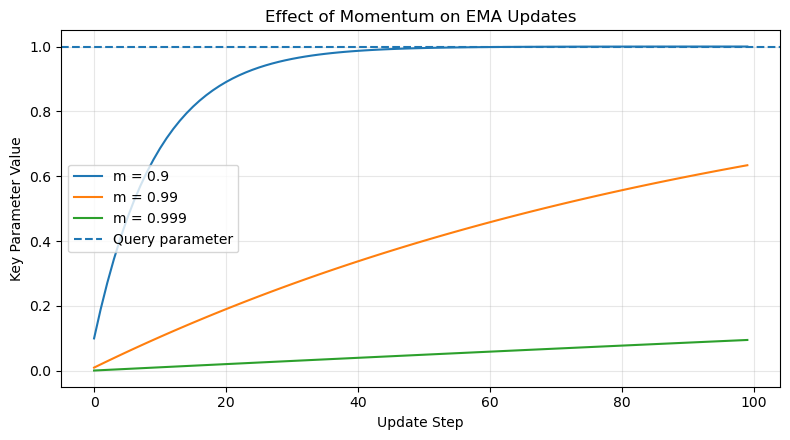

In [8]:
# 观察EMA更新

import numpy as np
import matplotlib.pyplot as plt

steps = 100
query_values = np.ones(steps)

momentums = [0.9, 0.99, 0.999]

fig, ax = plt.subplots(figsize=(8, 4.5))

for m in momentums:
    key_value = 0.0
    history = []

    for q_value in query_values:
        key_value = m * key_value + (1 - m) * q_value
        history.append(key_value)

    ax.plot(history, label=f"m = {m}")

ax.axhline(1.0, linestyle="--", label="Query parameter")

ax.set_xlabel("Update Step")
ax.set_ylabel("Key Parameter Value")
ax.set_title("Effect of Momentum on EMA Updates")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
